# Series 1 - Video 1 — GeoPandas

**Course:** Geospatial Data Science with Python


---

### Dataset

**Unfallatlas 2018 — Berlin road accidents**, 13,652 georeferenced crashes, published by the
Statistical Offices of the Federation and the States under *Datenlizenz Deutschland —
Namensnennung 2.0* (dl-de/by-2-0). Keep this attribution on screen:

> Unfallatlas 2018, Statistische Ämter des Bundes und der Länder, dl-de/by-2-0

## Setup


In [ ]:
!python --version

In [ ]:
import importlib, subprocess, sys

for mod, pkg in [("geopandas", "geopandas"), ("mapclassify", "mapclassify"),
                 ("pyarrow", "pyarrow")]:
    if importlib.util.find_spec(mod) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=True)

Install Libs if are not already installed.

In [ ]:
!python3 -m pip install --upgrade pip
!python3 -m pip install --only-binary=:all: geopandas mapclassify pyarrow
!python3 -m pip install matplotlib

## Load data

In [ ]:
import geopandas as gpd
import matplotlib.pyplot as plt

In [ ]:
import os, urllib.request

TS = "https://raw.githubusercontent.com/tagesspiegel/Unfallatlas-Berlin-2018/master/"
URLS = {
    "accidents_berlin_2018.geojson":       TS + "unfaelle_berlin_2018.geo.json",
    "street_segments_berlin_2018.geojson": TS + "unfaelle_berlin_2018_abschnitte.geo.json",
    "berlin_ortsteile.geojson":
        "https://raw.githubusercontent.com/codeforgermany/click_that_hood/main/public/data/berlin.geojson",
    "berlin_bezirke.geojson":
        "https://raw.githubusercontent.com/m-hoerz/berlin-shapes/master/berliner-bezirke.geojson",
}

def data_path(name, folder="data"):
    """Return a local path to a course dataset, downloading it only if needed."""
    for candidate in (os.path.join(folder, name), os.path.join("..", folder, name), name):
        if os.path.exists(candidate):
            return candidate
    os.makedirs(folder, exist_ok=True)
    target = os.path.join(folder, name)
    print("downloading", name, "...")
    urllib.request.urlretrieve(URLS[name], target)
    return target


CRS_METRIC = 25833
print("setup done")

In [ ]:
acc = gpd.read_file(data_path("accidents_berlin_2018.geojson"))

print(type(acc))
print(acc.shape)
acc.head(5)

**What the columns Say?**

In [ ]:
acc.columns



```
UMONAT: month of the accident (1-12)
USTUNDE: hour of the accident (0-23)
UKATEGORIE: accident severity category (for example, fatalities, serious injuries, or minor injuries only), stored as a code
ULICHTVERH: light conditions at the time (daylight, dusk, darkness, and so on), stored as a code
IstRad: 1 if a bicycle was involved
IstPKW: 1 if a passenger car was involved
IstFuss: 1 if a pedestrian was involved
IstKrad: 1 if a motorcycle was involved
IstGkfz: 1 if a heavy goods vehicle was involved
IstSonstig: 1 if another type of vehicle was involved
STRZUSTAND: road surface condition (dry, wet, icy, and so on), stored as a code
bezirk: Berlin district (Bezirk) where the accident occurred
oteil: Berlin local area (Ortsteil) where the accident occurred
dn_id: record identifier for the accident
geometry: the accident’s point location, stored as a geometry object in the GeoDataFrame’s coordinate system
```



In [ ]:
print("geometry column name:", acc.geometry.name)

In [ ]:
print("geometry column name:", acc.geometry.name)
print("geometry type      :", acc.geometry.geom_type.unique())
print("CRS                :", acc.crs)
print("bounds             :", acc.total_bounds.round(4))

### Pandas vs. geopandas

`groupby`, and `value_counts`

In [ ]:
type(acc["UKATEGORIE"])

In [ ]:
acc["UKATEGORIE"] = acc["UKATEGORIE"].astype(int)
acc["USTUNDE"] = acc["USTUNDE"].astype(int)

In [ ]:
print(acc["UKATEGORIE"].value_counts().sort_index(), "\n")

Ordinary pandas filtering

In [ ]:
night = acc[acc["USTUNDE"].between(0, 5)]
print("accidents between midnight and 6 am:", len(night))

ordinary pandas groupby

In [ ]:
acc.groupby("bezirk").size().sort_values(ascending=False).head(5)

---
## The geometry column

In [ ]:
first_geom = acc.geometry.iloc[0]
print(first_geom)
print("x, y:", round(first_geom.x, 5), round(first_geom.y, 5))

POINT (13.475018 52.513597)
x, y: 13.47502 52.5136


In [ ]:
acc.crs

<Geographic 2D CRS: EPSG:4326>
Name: WGS 84
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: World.
- bounds: (-180.0, -90.0, 180.0, 90.0)
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

In [ ]:
CRS_METRIC

25833

In [ ]:
acc_m = acc.to_crs(CRS_METRIC) # Coordinate Reference System (CRS)
print("unit:", acc_m.crs.axis_info[0].unit_name)

unit: metre


In [ ]:

centre = gpd.GeoSeries(gpd.points_from_xy([13.4010], [52.5190]), crs=4326).to_crs(CRS_METRIC).iloc[0]
acc_m["dist_centre_km"] = acc_m.distance(centre) / 1000

acc_m["dist_centre_km"].describe().round(2)


count    13652.00
mean         7.35
std          4.31
min          0.06
25%          3.96
50%          6.65
75%         10.40
max         25.83
Name: dist_centre_km, dtype: float64

### Polygons: area, centroid, dissolve

The same ideas on the neighbourhood boundaries.


In [ ]:
ortsteile = gpd.read_file(data_path("berlin_ortsteile.geojson"))[["name", "geometry"]]
ortsteile = ortsteile.rename(columns={"name": "ortsteil"}).to_crs(CRS_METRIC)

ortsteile["area_km2"] = ortsteile.geometry.area / 1e6
print("97 neighbourhoods, total area:", round(ortsteile["area_km2"].sum(), 1), "km²")


97 neighbourhoods, total area: 890.7 km²


In [ ]:
ortsteile.sort_values("area_km2", ascending=False).head(5)[["ortsteil", "area_km2"]]

,ortsteil,area_km2
66,Köpenick,34.849317
40,Tegel,33.620171
12,Wannsee,23.725358
51,Grunewald,22.343945
31,Müggelheim,22.206788


In [ ]:
# dissolve: merge many polygons into one
berlin = ortsteile.dissolve()
print("after dissolve:", len(berlin), "row,", berlin.geometry.iloc[0].geom_type)

after dissolve: 1 row, MultiPolygon


<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

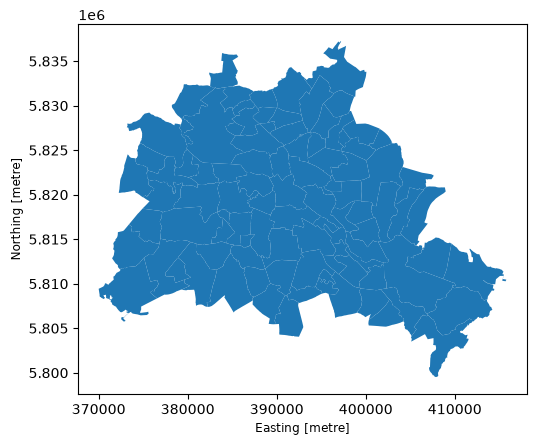

In [ ]:
ortsteile.plot()

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

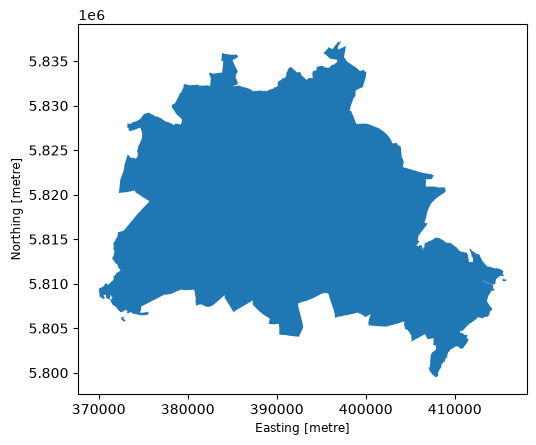

In [ ]:
berlin.plot()

In [ ]:
# centroid: one representative point per polygon
centroids = ortsteile.copy()
centroids["geometry"] = centroids.geometry.centroid
centroids.head(3)

,ortsteil,geometry,area_km2
0,Rahnsdorf,POINT (411843.525 5811231.151),21.429294
1,Rudow,POINT (397681.054 5808464.969),11.811703
2,Malchow,POINT (397515.742 5826353.896),1.517166


---
## Writing data, and why the format matters

Write the same layer four
ways and let the file sizes speak.


In [ ]:
import os, time

os.makedirs("out", exist_ok=True)

acc_m.to_file("out/accidents.shp")                       # legacy
acc_m.to_file("out/accidents.geojson", driver="GeoJSON")  # web exchange
acc_m.to_file("out/accidents.gpkg", layer="accidents", driver="GPKG")
acc_m.to_parquet("out/accidents.parquet")                 # analysis

def folder_size(stem):
    return sum(os.path.getsize("out/" + f) for f in os.listdir("out")
               if f.startswith(stem))

for label, stem in [("Shapefile (5 files!)", "accidents."),
                    ("GeoJSON", "accidents.geojson"),
                    ("GeoPackage", "accidents.gpkg"),
                    ("GeoParquet", "accidents.parquet")]:
    if stem == "accidents.":
        size = sum(os.path.getsize("out/accidents" + e) / 1e6
                   for e in [".shp", ".shx", ".dbf", ".prj", ".cpg"]
                   if os.path.exists("out/accidents" + e))
    else:
        size = os.path.getsize("out/" + stem) / 1e6
    print(f"{label:22s} {size:6.2f} MB")


/var/folders/pb/3hs3_9mn29v77k5hgm1804yr0000gn/T/ipykernel_1663/2512253879.py:5: UserWarning: Column names longer than 10 characters will be truncated when saved to ESRI Shapefile.
  acc_m.to_file("out/accidents.shp")                       # legacy
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/pyogrio/raw.py:733: RuntimeWarning: Normalized/laundered field name: 'dist_centre_km' to 'dist_centr'
  ogr_write(


Shapefile (5 files!)    16.12 MB
GeoJSON                  5.96 MB
GeoPackage               2.26 MB
GeoParquet               0.51 MB


In [ ]:
# read speed, same data
for label, fn in [("GeoJSON", lambda: gpd.read_file("out/accidents.geojson")),
                  ("GeoPackage", lambda: gpd.read_file("out/accidents.gpkg")),
                  ("GeoParquet", lambda: gpd.read_parquet("out/accidents.parquet"))]:
    t0 = time.perf_counter()
    fn()
    print(f"{label:12s} {time.perf_counter() - t0:5.2f} s")


GeoJSON       0.70 s
GeoPackage    0.16 s
GeoParquet    0.22 s


In [ ]:
# GeoPackage: several layers
ortsteile.to_file("out/berlin.gpkg", layer="ortsteile", driver="GPKG")
acc_m.to_file("out/berlin.gpkg", layer="accidents", driver="GPKG")

print(gpd.list_layers("out/berlin.gpkg"))


        name geometry_type
0  ortsteile  MultiPolygon
1  accidents         Point


---
## The first map


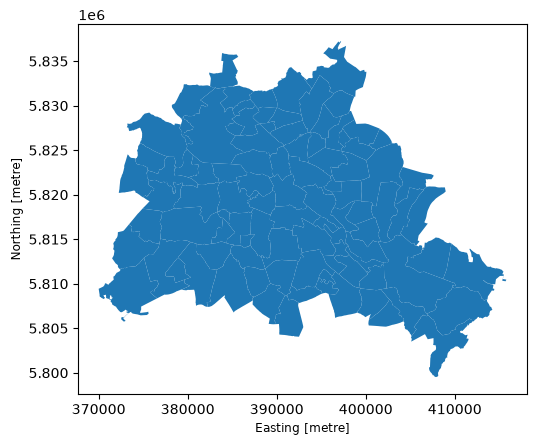

In [ ]:

ortsteile.plot()
plt.show()


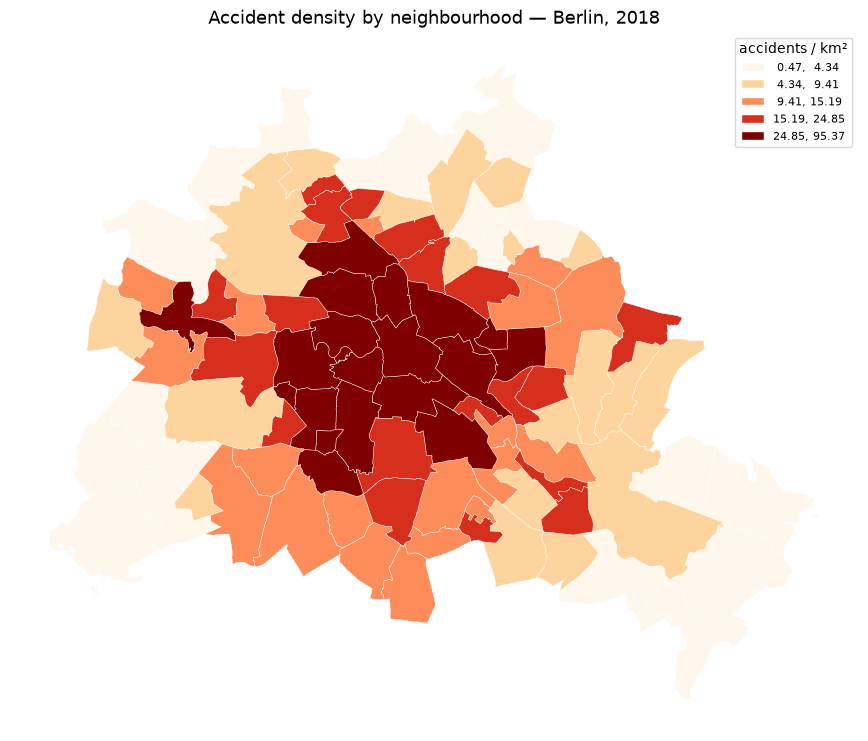

In [ ]:
# count accidents per neighbourhood, then map it
joined = gpd.sjoin(acc_m, ortsteile[["ortsteil", "geometry"]],
                   how="inner", predicate="within")
counts = joined.groupby("ortsteil").size().rename("n_accidents")

ot = ortsteile.join(counts, on="ortsteil").fillna({"n_accidents": 0})
ot["per_km2"] = ot["n_accidents"] / ot["area_km2"]

fig, ax = plt.subplots(figsize=(9, 7.5))
ot.plot(column="per_km2", scheme="quantiles", k=5, cmap="OrRd",
        edgecolor="white", linewidth=0.3, legend=True, ax=ax,
        legend_kwds={"title": "accidents / km²", "fontsize": 8})
ax.set_title("Accident density by neighbourhood — Berlin, 2018", fontsize=13)
ax.set_axis_off()
plt.tight_layout()
plt.show()


**What Next?** ⏭



The CRS mistakes everyone makes — why the same polygon has two different areas,
and how to never get it wrong again.
